In [1]:
import gc
import torch

# Clear Python garbage
gc.collect()

# Clear CUDA cache
if torch.cuda.is_available():
    torch.cuda.empty_cache()
    torch.cuda.ipc_collect()

print("GPU memory cleared.")

GPU memory cleared.


In [2]:
if torch.cuda.is_available():
    print(torch.cuda.memory_summary())
else:
    print("CUDA is not available.")

|===========================================================================|
|                  PyTorch CUDA memory summary, device ID 0                 |
|---------------------------------------------------------------------------|
|            CUDA OOMs: 0            |        cudaMalloc retries: 0         |
|===========================================================================|
|        Metric         | Cur Usage  | Peak Usage | Tot Alloc  | Tot Freed  |
|---------------------------------------------------------------------------|
| Allocated memory      |      0 B   |      0 B   |      0 B   |      0 B   |
|       from large pool |      0 B   |      0 B   |      0 B   |      0 B   |
|       from small pool |      0 B   |      0 B   |      0 B   |      0 B   |
|---------------------------------------------------------------------------|
| Active memory         |      0 B   |      0 B   |      0 B   |      0 B   |
|       from large pool |      0 B   |      0 B   |      0 B   |

In [3]:
# ==========================================
# NeurALLNet Version-04
# Environment Setup
# ==========================================
!pip install -q spikingjelly
import spikingjelly
import os
import random
import numpy as np
import pandas as pd

import torch
import torch.nn as nn
import torch.optim as optim

import matplotlib.pyplot as plt
import seaborn as sns

from tqdm.auto import tqdm
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

from spikingjelly.activation_based import neuron, surrogate, functional

# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

# Device
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("NeurALLNet Version-04")
print("======================")
print("PyTorch:", torch.__version__)
print("CUDA Available:", torch.cuda.is_available())
print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "GPU Memory:",
        round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2),
        "GB"
    )

NeurALLNet Version-04
PyTorch: 2.11.0+cu128
CUDA Available: True
Device: cuda
GPU: Tesla T4
GPU Memory: 14.56 GB


In [4]:
import os

print("Kaggle input directories:\n")

for item in os.listdir("/kaggle/input"):
    print(item)

Kaggle input directories:

datasets


In [5]:
import os

DATA_ROOT = "/kaggle/input/datasets"

for root, dirs, files in os.walk(DATA_ROOT):
    level = root.replace(DATA_ROOT, "").count(os.sep)

    if level > 3:
        dirs[:] = []
        continue

    indent = "    " * level
    print(f"{indent}{os.path.basename(root)}/")

    for file in files[:8]:
        print(f"{indent}    {file}")

    if len(files) > 8:
        print(f"{indent}    ... and {len(files)-8} more files")

datasets/
    faiznadeem39/
        milk10k/
            MILK10k_Training_GroundTruth.csv
            MILK10k_Training_Metadata.csv
            MILK10k_Training_Supplement.csv
            MILK10k_Training_Input/


In [6]:
# ==========================================
# Dataset Path Configuration
# ==========================================

DATA_ROOT = "/kaggle/input/datasets/faiznadeem39/milk10k"

GROUND_TRUTH_CSV = os.path.join(
    DATA_ROOT, "MILK10k_Training_GroundTruth.csv"
)

METADATA_CSV = os.path.join(
    DATA_ROOT, "MILK10k_Training_Metadata.csv"
)

IMAGE_ROOT = os.path.join(
    DATA_ROOT,
    "MILK10k_Training_Input",
    "MILK10k_Training_Input"
)

# Verify paths
print("Ground Truth:", os.path.exists(GROUND_TRUTH_CSV))
print("Metadata:", os.path.exists(METADATA_CSV))
print("Image Root:", os.path.exists(IMAGE_ROOT))

print("\nImage directory contents:")
if os.path.exists(IMAGE_ROOT):
    print(os.listdir(IMAGE_ROOT)[:10])

Ground Truth: True
Metadata: True
Image Root: True

Image directory contents:
['IL_0000652', 'IL_0003176', 'IL_0004688', 'IL_0005081', 'IL_0006177', 'IL_0006407', 'IL_0008891', 'IL_0008969', 'IL_0009339', 'IL_0011263']


In [7]:
# ==========================================
# Load MILK10k CSV Files
# ==========================================

ground_truth_df = pd.read_csv(GROUND_TRUTH_CSV)
metadata_df = pd.read_csv(METADATA_CSV)


print("GROUND TRUTH")
print("Shape:", ground_truth_df.shape)
print("Columns:", ground_truth_df.columns.tolist())
display(ground_truth_df.head())

print("\nMETADATA")
print("Shape:", metadata_df.shape)
print("Columns:", metadata_df.columns.tolist())
display(metadata_df.head())


GROUND TRUTH
Shape: (5240, 12)
Columns: ['lesion_id', 'AKIEC', 'BCC', 'BEN_OTH', 'BKL', 'DF', 'INF', 'MAL_OTH', 'MEL', 'NV', 'SCCKA', 'VASC']


,lesion_id,AKIEC,BCC,BEN_OTH,BKL,DF,INF,MAL_OTH,MEL,NV,SCCKA,VASC
0,IL_0000652,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,IL_0003176,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,IL_0004688,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,IL_0005081,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
4,IL_0006177,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0



METADATA
Shape: (10480, 17)
Columns: ['lesion_id', 'image_type', 'isic_id', 'attribution', 'copyright_license', 'image_manipulation', 'age_approx', 'sex', 'skin_tone_class', 'site', 'MONET_ulceration_crust', 'MONET_hair', 'MONET_vasculature_vessels', 'MONET_erythema', 'MONET_pigmented', 'MONET_gel_water_drop_fluid_dermoscopy_liquid', 'MONET_skin_markings_pen_ink_purple_pen']


,lesion_id,image_type,isic_id,attribution,copyright_license,image_manipulation,age_approx,sex,skin_tone_class,site,MONET_ulceration_crust,MONET_hair,MONET_vasculature_vessels,MONET_erythema,MONET_pigmented,MONET_gel_water_drop_fluid_dermoscopy_liquid,MONET_skin_markings_pen_ink_purple_pen
0,IL_0000652,clinical: close-up,ISIC_8149219,MILK study team,CC-BY-NC,altered,70.0,male,1,head_neck_face,0.166749,0.163601,0.002284,0.124315,0.719495,0.220399,0.237601
1,IL_0000652,dermoscopic,ISIC_4671410,MILK study team,CC-BY-NC,instrument only,70.0,male,1,head_neck_face,0.659859,0.156478,0.016397,0.032357,0.847014,0.138121,0.148776
2,IL_0003176,clinical: close-up,ISIC_3904045,MILK study team,CC-BY-NC,instrument only,45.0,female,5,head_neck_face,0.348609,0.614718,0.013415,0.447485,0.061977,0.296341,0.058006
3,IL_0003176,dermoscopic,ISIC_5371928,MILK study team,CC-BY-NC,instrument only,45.0,female,5,head_neck_face,0.392950,0.897668,0.367882,0.645776,0.122108,0.719937,0.329812
4,IL_0004688,clinical: close-up,ISIC_0791494,MILK study team,CC-BY-NC,instrument only,50.0,male,3,lower_extremity,0.889925,0.120788,0.004546,0.487298,0.036550,0.146776,0.086027


In [8]:
# ==========================================
# Original Class Distribution
# ==========================================

class_columns = [
    col for col in ground_truth_df.columns
    if col != "lesion_id"
]

class_counts = ground_truth_df[class_columns].sum().astype(int)

print("Total lesions:", len(ground_truth_df))
print("Total classes:", len(class_columns))

print("\nOriginal Class Distribution:\n")

for class_name, count in class_counts.items():
    print(f"{class_name:10s}: {count}")

print("\nTotal samples:", class_counts.sum())

Total lesions: 5240
Total classes: 11

Original Class Distribution:

AKIEC     : 303
BCC       : 2522
BEN_OTH   : 44
BKL       : 544
DF        : 52
INF       : 50
MAL_OTH   : 9
MEL       : 450
NV        : 746
SCCKA     : 473
VASC      : 47

Total samples: 5240


In [9]:
# ==========================================
# NeurALLNet V04 - Correct Six Class Filtering
# ==========================================

class_names = ["BCC", "NV", "BKL", "SCCKA", "MEL"]

# Select the five target classes
filtered_gt = ground_truth_df[
    ["lesion_id"] + class_names
].copy()

# Remove lesions belonging to excluded classes
filtered_gt = filtered_gt[filtered_gt[class_names].sum(axis=1) == 1].copy()

# Assign class labels
filtered_gt["label"] = filtered_gt[class_names].idxmax(axis=1)

# Encode labels
label_to_idx = {
    name: idx for idx, name in enumerate(class_names)
}

filtered_gt["label_idx"] = filtered_gt["label"].map(label_to_idx)

print("Retained lesions:", len(filtered_gt))

print("\nClass distribution:")
print(filtered_gt["label"].value_counts().reindex(class_names))

print("\nMissing labels:", filtered_gt["label_idx"].isna().sum())
print("Duplicate lesion IDs:", filtered_gt["lesion_id"].duplicated().sum())

Retained lesions: 4735

Class distribution:
label
BCC      2522
NV        746
BKL       544
SCCKA     473
MEL       450
Name: count, dtype: int64

Missing labels: 0
Duplicate lesion IDs: 0


In [10]:
paired_metadata = metadata_df[
    metadata_df["lesion_id"].isin(filtered_gt["lesion_id"])
].copy()

print("Image type distribution:")
print(paired_metadata["image_type"].value_counts())

print("\nUnique lesions:", paired_metadata["lesion_id"].nunique())

print("\nDuplicate lesion-image type pairs:",
      paired_metadata.duplicated(
          subset=["lesion_id", "image_type"]
      ).sum())

print("\nImage types:", paired_metadata["image_type"].unique())

Image type distribution:
image_type
clinical: close-up    4735
dermoscopic           4735
Name: count, dtype: int64

Unique lesions: 4735

Duplicate lesion-image type pairs: 0

Image types: ['clinical: close-up' 'dermoscopic']


In [11]:
paired_images = paired_metadata.pivot(
    index="lesion_id",
    columns="image_type",
    values="isic_id"
).reset_index()

paired_df = filtered_gt[
    ["lesion_id", "label", "label_idx"]
].merge(
    paired_images,
    on="lesion_id",
    how="inner",
    validate="one_to_one"
)

paired_df = paired_df.rename(columns={
    "clinical: close-up": "clinical_image",
    "dermoscopic": "dermoscopic_image"
})

print("Paired dataset shape:", paired_df.shape)
print("\nMissing clinical images:",
      paired_df["clinical_image"].isna().sum())
print("Missing dermoscopic images:",
      paired_df["dermoscopic_image"].isna().sum())

display(paired_df.head())

Paired dataset shape: (4735, 5)

Missing clinical images: 0
Missing dermoscopic images: 0


,lesion_id,label,label_idx,clinical_image,dermoscopic_image
0,IL_0000652,BCC,0,ISIC_8149219,ISIC_4671410
1,IL_0003176,BCC,0,ISIC_3904045,ISIC_5371928
2,IL_0004688,BCC,0,ISIC_0791494,ISIC_3624913
3,IL_0005081,SCCKA,3,ISIC_5667730,ISIC_5186409
4,IL_0006177,BCC,0,ISIC_8803389,ISIC_1048297


In [12]:
# Verify actual image files for sample lesions

for _, row in paired_df.head(5).iterrows():

    lesion_folder = os.path.join(
        IMAGE_ROOT, row["lesion_id"]
    )

    files = os.listdir(lesion_folder)

    clinical_exists = any(
        f.startswith(row["clinical_image"])
        for f in files
    )

    dermoscopic_exists = any(
        f.startswith(row["dermoscopic_image"])
        for f in files
    )

    print(
        row["lesion_id"],
        "| Clinical:", clinical_exists,
        "| Dermoscopic:", dermoscopic_exists
    )

IL_0000652 | Clinical: True | Dermoscopic: True
IL_0003176 | Clinical: True | Dermoscopic: True
IL_0004688 | Clinical: True | Dermoscopic: True
IL_0005081 | Clinical: True | Dermoscopic: True
IL_0006177 | Clinical: True | Dermoscopic: True


In [13]:
from sklearn.model_selection import train_test_split

# First split: 80% training, 20% temporary
train_df, temp_df = train_test_split(
    paired_df,
    test_size=0.20,
    random_state=42,
    stratify=paired_df["label_idx"]
)

# Second split: 10% validation, 10% test
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42,
    stratify=temp_df["label_idx"]
)

# Verify split sizes
print("========== DATA SPLIT ==========")
print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Testing:", len(test_df))
print("Total:", len(train_df) + len(val_df) + len(test_df))

# Verify class distribution
for split_name, split_df in [
    ("TRAIN", train_df),
    ("VALIDATION", val_df),
    ("TEST", test_df)
]:
    print(f"\n{split_name} CLASS DISTRIBUTION:")
    print(
        split_df["label"].value_counts()
        .reindex(class_names, fill_value=0)
    )

# Verify lesion-level separation
train_ids = set(train_df["lesion_id"])
val_ids = set(val_df["lesion_id"])
test_ids = set(test_df["lesion_id"])

print("\n========== OVERLAP CHECK ==========")
print("Train-Val:", len(train_ids & val_ids))
print("Train-Test:", len(train_ids & test_ids))
print("Val-Test:", len(val_ids & test_ids))

========== DATA SPLIT ==========
Training: 3788
Validation: 473
Testing: 474
Total: 4735

TRAIN CLASS DISTRIBUTION:
label
BCC      2018
NV        597
BKL       435
SCCKA     378
MEL       360
Name: count, dtype: int64

VALIDATION CLASS DISTRIBUTION:
label
BCC      252
NV        74
BKL       54
SCCKA     48
MEL       45
Name: count, dtype: int64

TEST CLASS DISTRIBUTION:
label
BCC      252
NV        75
BKL       55
SCCKA     47
MEL       45
Name: count, dtype: int64

========== OVERLAP CHECK ==========
Train-Val: 0
Train-Test: 0
Val-Test: 0


In [14]:
# Training-only class weights
train_counts = (
    train_df["label_idx"]
    .value_counts()
    .reindex(range(len(class_names)))
)

counts_tensor = torch.tensor(
    train_counts.values,
    dtype=torch.float32
)

# Inverse-frequency weights
alpha = 1.0 / counts_tensor

# Normalize alpha to mean 1
alpha = alpha / alpha.mean()

alpha = alpha.to(device)

GAMMA = 2.0

print("Training class counts:")
print(train_counts)

print("\nFocal Loss alpha weights:")
for name, weight in zip(class_names, alpha.cpu().numpy()):
    print(f"{name:8s}: {weight:.4f}")

print("\nAlpha mean:", alpha.mean().item())
print("Gamma:", GAMMA)

Training class counts:
label_idx
0    2018
1     597
2     435
3     378
4     360
Name: count, dtype: int64

Focal Loss alpha weights:
BCC     : 0.2505
NV      : 0.8466
BKL     : 1.1619
SCCKA   : 1.3371
MEL     : 1.4040

Alpha mean: 1.0
Gamma: 2.0


In [15]:
sample_lesion = paired_df.iloc[0]["lesion_id"]

sample_folder = os.path.join(IMAGE_ROOT, sample_lesion)

print("Lesion:", sample_lesion)
print("\nFiles:")

for filename in os.listdir(sample_folder):
    print(filename)

Lesion: IL_0000652

Files:
ISIC_4671410.jpg
ISIC_8149219.jpg


In [16]:
    
    # ==========================================
    # Paired Dataset and Augmentation - Version 4-c
    # No Random Augmentation
    # ==========================================
    
    import os
    import torch
    from PIL import Image
    from torch.utils.data import Dataset, DataLoader
    from torchvision.transforms import functional as TF
    
    
    # ImageNet normalization
    MEAN = [0.485, 0.456, 0.406]
    STD = [0.229, 0.224, 0.225]
    
    
    # Paired Transform (No Augmentation)
    class PairedTransform:
    
        def __init__(self, size=224):
            self.size = size
    
        def __call__(self, clinical, dermoscopic):
    
            # Resize both modalities
            clinical = TF.resize(
                clinical, (self.size, self.size)
            )
    
            dermoscopic = TF.resize(
                dermoscopic, (self.size, self.size)
            )
    
            # Convert to tensors
            clinical = TF.to_tensor(clinical)
            dermoscopic = TF.to_tensor(dermoscopic)
    
            # ImageNet normalization
            clinical = TF.normalize(
                clinical, MEAN, STD
            )
    
            dermoscopic = TF.normalize(
                dermoscopic, MEAN, STD
            )
    
            return clinical, dermoscopic
    
    
    # ==========================================
    # Paired MILK10k Dataset
    # ==========================================
    
    class MILK10kPairedDataset(Dataset):
    
        def __init__(self, dataframe, image_root, transform=None):
            self.df = dataframe.reset_index(drop=True)
            self.image_root = image_root
            self.transform = transform
    
        def __len__(self):
            return len(self.df)
    
        def __getitem__(self, idx):
    
            row = self.df.iloc[idx]
    
            lesion_folder = os.path.join(
                self.image_root, row["lesion_id"]
            )
    
            clinical_path = os.path.join(
                lesion_folder, row["clinical_image"] + ".jpg"
            )
    
            dermoscopic_path = os.path.join(
                lesion_folder, row["dermoscopic_image"] + ".jpg"
            )
    
            clinical = Image.open(clinical_path).convert("RGB")
            dermoscopic = Image.open(dermoscopic_path).convert("RGB")
    
            if self.transform:
                clinical, dermoscopic = self.transform(
                    clinical, dermoscopic
                )
    
            label = torch.tensor(
                row["label_idx"], dtype=torch.long
            )
    
            return clinical, dermoscopic, label
    
    
    # ==========================================
    # Define Transformations
    # ==========================================
    
    train_transform = PairedTransform(size=224)
    
    val_test_transform = PairedTransform(size=224)
    
    
    # ==========================================
    # Create Datasets
    # ==========================================
    
    train_dataset = MILK10kPairedDataset(
        train_df, IMAGE_ROOT, train_transform
    )
    
    val_dataset = MILK10kPairedDataset(
        val_df, IMAGE_ROOT, val_test_transform
    )
    
    test_dataset = MILK10kPairedDataset(
        test_df, IMAGE_ROOT, val_test_transform
    )
    
    
    print("Train dataset:", len(train_dataset))
    print("Validation dataset:", len(val_dataset))
    print("Test dataset:", len(test_dataset))
    
    print("\nPaired datasets created successfully.")
    print("Random augmentation: DISABLED")
    print("Image size: 224 x 224")
    print("Normalization: ImageNet")


Train dataset: 3788
Validation dataset: 473
Test dataset: 474

Paired datasets created successfully.
Random augmentation: DISABLED
Image size: 224 x 224
Normalization: ImageNet


In [17]:
BATCH_SIZE = 8

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=True,
    drop_last=False
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

# Verify one batch
clinical, dermoscopic, labels = next(iter(train_loader))

print("\nClinical:", clinical.shape)
print("Dermoscopic:", dermoscopic.shape)
print("Labels:", labels.shape)
print("Label values:", labels.unique().tolist())

Train batches: 474
Validation batches: 60
Test batches: 60

Clinical: torch.Size([8, 3, 224, 224])
Dermoscopic: torch.Size([8, 3, 224, 224])
Labels: torch.Size([8])
Label values: [0, 1, 2, 3]


In [18]:
class FocalLoss(nn.Module):
    def __init__(self, alpha=None, gamma=2.0):
        super().__init__()
        self.gamma = gamma

        if alpha is not None:
            self.register_buffer("alpha", alpha)
        else:
            self.alpha = None

    def forward(self, inputs, targets):

        log_probs = torch.nn.functional.log_softmax(
            inputs, dim=1
        )

        log_pt = log_probs.gather(
            1, targets.unsqueeze(1)
        ).squeeze(1)

        pt = log_pt.exp()

        focal_factor = (1.0 - pt) ** self.gamma

        loss = -focal_factor * log_pt

        if self.alpha is not None:
            alpha_t = self.alpha[targets]
            loss = alpha_t * loss

        return loss.mean()


criterion = FocalLoss(
    alpha=alpha,
    gamma=GAMMA
).to(device)

print("Loss:", criterion.__class__.__name__)
print("Gamma:", criterion.gamma)
print("Alpha:", criterion.alpha)

Loss: FocalLoss
Gamma: 2.0
Alpha: tensor([0.2505, 0.8466, 1.1619, 1.3371, 1.4040], device='cuda:0')


In [19]:
# Focal Loss sanity check
sample_logits = torch.randn(
    8, len(class_names),
    device=device,
    requires_grad=True
)

sample_labels = torch.randint(
    0, len(class_names), (8,),
    device=device
)

sample_loss = criterion(sample_logits, sample_labels)

sample_loss.backward()

print("Sample loss:", sample_loss.item())
print("Loss is finite:", torch.isfinite(sample_loss).item())
print("Gradients available:", sample_logits.grad is not None)
print("Gradients finite:", torch.isfinite(sample_logits.grad).all().item())

Sample loss: 2.026808261871338
Loss is finite: True
Gradients available: True
Gradients finite: True


In [20]:

import torch
import torch.nn as nn
from spikingjelly.activation_based import neuron, surrogate, functional


# 1. Squeeze-and-Excitation Block
class SEBlock(nn.Module):
    def __init__(self, channels, reduction=4):
        super().__init__()

        mid = max(channels // reduction, 8)

        self.squeeze = nn.AdaptiveAvgPool2d(1)

        self.excitation = nn.Sequential(
            nn.Linear(channels, mid, bias=False),
            nn.ReLU(inplace=True),
            nn.Linear(mid, channels, bias=False),
            nn.Sigmoid()
        )

    def forward(self, x):
        b, c, _, _ = x.shape

        weights = self.squeeze(x).view(b, c)
        weights = self.excitation(weights).view(b, c, 1, 1)

        return x * weights


# 2. Depthwise Separable Convolution
class DepthwiseSeparableConv(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()

        self.depthwise = nn.Conv2d(
            in_ch,
            in_ch,
            kernel_size=3,
            padding=1,
            groups=in_ch,
            bias=False
        )

        self.bn_dw = nn.BatchNorm2d(in_ch)

        self.pointwise = nn.Conv2d(
            in_ch,
            out_ch,
            kernel_size=1,
            bias=False
        )

        self.bn_pw = nn.BatchNorm2d(out_ch)

    def forward(self, x):
        x = self.bn_dw(self.depthwise(x))
        x = self.bn_pw(self.pointwise(x))

        return x


# 3. Spiking Block
class SpikeBlock(nn.Module):
    def __init__(self, in_ch, out_ch, tau=2.0):
        super().__init__()

        self.conv = DepthwiseSeparableConv(in_ch, out_ch)

        self.se = SEBlock(out_ch)

        self.lif = neuron.LIFNode(
            tau=tau,
            v_threshold=1.0,
            surrogate_function=surrogate.ATan(alpha=2.0),
            step_mode='s'
        )

        self.pool = nn.MaxPool2d(2, 2)

    def forward(self, x):
        x = self.conv(x)
        x = self.se(x)
        x = self.lif(x)
        x = self.pool(x)

        return x


# 4. NeurALLNet Feature Extractor
class NeurALLFeatureExtractor(nn.Module):
    def __init__(self):
        super().__init__()

        tau = 2.0

        self.stem = nn.Sequential(
            nn.Conv2d(
                3, 48,
                kernel_size=3,
                padding=1,
                bias=False
            ),
            nn.BatchNorm2d(48),

            neuron.LIFNode(
                tau=tau,
                v_threshold=1.0,
                surrogate_function=surrogate.ATan(alpha=2.0),
                step_mode='s'
            ),

            nn.MaxPool2d(2, 2)
        )

        self.block1 = SpikeBlock(48, 96, tau)
        self.block2 = SpikeBlock(96, 192, tau)
        self.block3 = SpikeBlock(192, 384, tau)

        self.refine = nn.Sequential(
            nn.Conv2d(
                384, 384,
                kernel_size=3,
                padding=1,
                groups=384,
                bias=False
            ),
            nn.BatchNorm2d(384),

            nn.Conv2d(
                384, 256,
                kernel_size=1,
                bias=False
            ),
            nn.BatchNorm2d(256),

            neuron.LIFNode(
                tau=tau,
                v_threshold=1.0,
                surrogate_function=surrogate.ATan(alpha=2.0),
                step_mode='s'
            )
        )

        self.gap = nn.AdaptiveAvgPool2d(1)

    def forward(self, x):
        x = self.stem(x)
        x = self.block1(x)
        x = self.block2(x)
        x = self.block3(x)
        x = self.refine(x)
        x = self.gap(x).flatten(1)

        return x


# 5. Dual-Branch NeurALLNet
class DualBranchNeurALLNet(nn.Module):

    def __init__(self, num_classes=6, time_steps=4):
        super().__init__()

        self.T = time_steps

        self.clinical_branch = NeurALLFeatureExtractor()
        self.dermoscopic_branch = NeurALLFeatureExtractor()

        self.classifier = nn.Sequential(
            nn.Linear(512, 128, bias=False),
            nn.BatchNorm1d(128),
            neuron.LIFNode(
                tau=2.0,
                v_threshold=1.0,
                surrogate_function=surrogate.ATan(alpha=2.0),
                step_mode='s'
            ),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes, bias=False)
        )

    def forward(self, clinical, dermoscopic):

        functional.reset_net(self)

        output_sum = None

        for t in range(self.T):

            clinical_features = self.clinical_branch(clinical)

            dermoscopic_features = self.dermoscopic_branch(
                dermoscopic
            )

            fused_features = torch.cat(
                (clinical_features, dermoscopic_features),
                dim=1
            )

            output = self.classifier(fused_features)

            if output_sum is None:
                output_sum = output
            else:
                output_sum = output_sum + output

        return output_sum / self.T


print("All architecture classes defined successfully.")


All architecture classes defined successfully.


In [21]:
model = DualBranchNeurALLNet(
    num_classes=len(class_names),
    time_steps=4
).to(device)

In [23]:
# Forward Pass Verification

model.eval()

clinical_batch, dermoscopic_batch, labels = next(iter(train_loader))

clinical_batch = clinical_batch.to(device)
dermoscopic_batch = dermoscopic_batch.to(device)

with torch.no_grad():
    functional.reset_net(model)
    outputs = model(clinical_batch, dermoscopic_batch)

print("Clinical input shape:", clinical_batch.shape)
print("Dermoscopic input shape:", dermoscopic_batch.shape)
print("Labels shape:", labels.shape)
print("Model output shape:", outputs.shape)

print("\nExpected output shape:", (8, 6))
print("Forward pass successful:", outputs.shape == (8, 6))

Clinical input shape: torch.Size([8, 3, 224, 224])
Dermoscopic input shape: torch.Size([8, 3, 224, 224])
Labels shape: torch.Size([8])
Model output shape: torch.Size([8, 5])

Expected output shape: (8, 6)
Forward pass successful: False


In [24]:
import torch.optim as optim

learning_rate = 0.001

optimizer = optim.Adam(
    model.parameters(),
    lr=learning_rate
)

In [25]:
# Training Configuration

NUM_EPOCHS = 50
PATIENCE = 10

best_val_f1 = 0.0
early_stop_counter = 0

history = {
    "train_loss": [],
    "train_acc": [],
    "train_f1": [],
    "val_loss": [],
    "val_acc": [],
    "val_f1": []
}

print("Epochs:", NUM_EPOCHS)
print("Early Stopping Patience:", PATIENCE)
print("Checkpoint Selection Metric: Macro F1")
print("Training configuration initialized.")

Epochs: 50
Early Stopping Patience: 10
Checkpoint Selection Metric: Macro F1
Training configuration initialized.


In [26]:
    
    # ==========================================
    # NeurALLNet Version-04
    # Training Loop with Macro F1 Checkpointing
    # ==========================================
    
    import os
    import numpy as np
    from tqdm.auto import tqdm
    from sklearn.metrics import accuracy_score, f1_score
    
    
    # Checkpoint directory
    CHECKPOINT_DIR = "checkpoints_v4"
    os.makedirs(CHECKPOINT_DIR, exist_ok=True)
    
    # All six class indices
    class_indices = list(range(len(class_names)))
    
    # Best validation Macro F1
    best_val_f1 = -1.0
    early_stop_counter = 0
    
    
    for epoch in range(NUM_EPOCHS):
    
        # ======================================
        # TRAINING
        # ======================================
    
        model.train()
    
        train_losses = []
        train_labels = []
        train_preds = []
    
        train_bar = tqdm(
            train_loader,
            desc=f"Epoch {epoch+1}/{NUM_EPOCHS} [Train]"
        )
    
        for clinical, dermoscopic, labels in train_bar:
    
            clinical = clinical.to(device)
            dermoscopic = dermoscopic.to(device)
            labels = labels.to(device)
    
            optimizer.zero_grad()
    
            outputs = model(clinical, dermoscopic)
    
            loss = criterion(outputs, labels)
    
            loss.backward()
            optimizer.step()
    
            train_losses.append(loss.item())
    
            predictions = torch.argmax(
                outputs.detach(), dim=1
            )
    
            train_labels.extend(labels.detach().cpu().numpy())
            train_preds.extend(predictions.cpu().numpy())
    
            # Reset SNN states after each training batch
            functional.reset_net(model)
    
            train_bar.set_postfix(
                loss=f"{loss.item():.4f}"
            )
    
            del clinical, dermoscopic, labels
            del outputs, loss, predictions
    
        train_loss = np.mean(train_losses)
    
        train_acc = accuracy_score(
            train_labels, train_preds
        )
    
        train_f1 = f1_score(
            train_labels,
            train_preds,
            labels=class_indices,
            average="macro",
            zero_division=0
        )
    
    
        # ======================================
        # VALIDATION
        # ======================================
    
        model.eval()
    
        val_losses = []
        val_labels = []
        val_preds = []
    
        with torch.no_grad():
    
            val_bar = tqdm(
                val_loader,
                desc=f"Epoch {epoch+1}/{NUM_EPOCHS} [Val]"
            )
    
            for clinical, dermoscopic, labels in val_bar:
    
                clinical = clinical.to(device)
                dermoscopic = dermoscopic.to(device)
                labels = labels.to(device)
    
                outputs = model(clinical, dermoscopic)
    
                loss = criterion(outputs, labels)
    
                val_losses.append(loss.item())
    
                predictions = torch.argmax(
                    outputs, dim=1
                )
    
                val_labels.extend(labels.cpu().numpy())
                val_preds.extend(predictions.cpu().numpy())
    
                # Reset SNN states after each validation batch
                functional.reset_net(model)
    
                del clinical, dermoscopic, labels
                del outputs, loss, predictions
    
    
        val_loss = np.mean(val_losses)
    
        val_acc = accuracy_score(
            val_labels, val_preds
        )
    
        val_f1 = f1_score(
            val_labels,
            val_preds,
            labels=class_indices,
            average="macro",
            zero_division=0
        )
    
    
        # ======================================
        # SAVE TRAINING HISTORY
        # ======================================
    
        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["train_f1"].append(train_f1)
    
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)
        history["val_f1"].append(val_f1)
    
    
        # ======================================
        # EPOCH RESULTS
        # ======================================
    
        print(f"\nEpoch [{epoch+1}/{NUM_EPOCHS}]")
    
        print(
            f"Train Loss: {train_loss:.4f} | "
            f"Train Acc: {train_acc:.4f} | "
            f"Train Macro F1: {train_f1:.4f}"
        )
    
        print(
            f"Val Loss: {val_loss:.4f} | "
            f"Val Acc: {val_acc:.4f} | "
            f"Val Macro F1: {val_f1:.4f}"
        )
    
    
        # ======================================
        # BEST MODEL CHECKPOINT
        # ======================================
    
        if val_f1 > best_val_f1:
    
            best_val_f1 = val_f1
            early_stop_counter = 0
    
            checkpoint = {
                "epoch": epoch + 1,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "best_val_f1": best_val_f1,
                "class_names": class_names,
                "history": history
            }
    
            torch.save(
                checkpoint,
                os.path.join(CHECKPOINT_DIR, "best_model.pth")
            )
    
            print(
                f"Best model saved! "
                f"Validation Macro F1: {best_val_f1:.4f}"
            )
    
        else:
    
            early_stop_counter += 1
    
            print(
                f"No improvement: "
                f"{early_stop_counter}/{PATIENCE}"
            )
    
    
        # ======================================
        # EARLY STOPPING
        # ======================================
    
        if early_stop_counter >= PATIENCE:
    
            print("\nEarly stopping triggered.")
            break
    
    
        # Memory cleanup
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
    
    
    # ======================================
    # TRAINING COMPLETED
    # ======================================
    
    print("\nTraining completed.")
    
    print(
        f"Best Validation Macro F1: {best_val_f1:.4f}"
    )
    
    print(
        f"Best model location: "
        f"{CHECKPOINT_DIR}/best_model.pth"
    )


Epoch 1/50 [Train]:   0%|          | 0/474 [00:00<?, ?it/s]

Epoch 1/50 [Val]:   0%|          | 0/60 [00:00<?, ?it/s]


Epoch [1/50]
Train Loss: 0.5782 | Train Acc: 0.4488 | Train Macro F1: 0.3352
Val Loss: 0.5622 | Val Acc: 0.5856 | Val Macro F1: 0.3928
Best model saved! Validation Macro F1: 0.3928


Epoch 2/50 [Train]:   0%|          | 0/474 [00:00<?, ?it/s]

Epoch 2/50 [Val]:   0%|          | 0/60 [00:00<?, ?it/s]


Epoch [2/50]
Train Loss: 0.4953 | Train Acc: 0.4789 | Train Macro F1: 0.3779
Val Loss: 0.4799 | Val Acc: 0.5962 | Val Macro F1: 0.3782
No improvement: 1/10


... (38 outputs left out)


Epoch [15/50]
Train Loss: 0.3743 | Train Acc: 0.5499 | Train Macro F1: 0.4808
Val Loss: 0.4180 | Val Acc: 0.5222 | Val Macro F1: 0.4639
No improvement: 9/10


Epoch 16/50 [Train]:   0%|          | 0/474 [00:00<?, ?it/s]

Epoch 16/50 [Val]:   0%|          | 0/60 [00:00<?, ?it/s]


Epoch [16/50]
Train Loss: 0.3800 | Train Acc: 0.5430 | Train Macro F1: 0.4731
Val Loss: 0.4039 | Val Acc: 0.5433 | Val Macro F1: 0.4756
No improvement: 10/10

Early stopping triggered.

Training completed.
Best Validation Macro F1: 0.4975
Best model location: checkpoints_v4/best_model.pth


In [27]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# 1. Load best checkpoint
checkpoint_path = "checkpoints_v4/best_model.pth"

checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=False
)

model.load_state_dict(checkpoint["model_state_dict"])
model.to(device)
model.eval()

print("Loaded best checkpoint from epoch:", checkpoint["epoch"])
print("Best Validation Macro F1:", checkpoint["best_val_f1"])

# 2. Test evaluation
all_labels = []
all_predictions = []

with torch.no_grad():

    for clinical, dermoscopic, labels in test_loader:

        clinical = clinical.to(device)
        dermoscopic = dermoscopic.to(device)
        labels = labels.to(device)

        outputs = model(clinical, dermoscopic)
        predictions = torch.argmax(outputs, dim=1)

        all_labels.extend(labels.cpu().numpy())
        all_predictions.extend(predictions.cpu().numpy())

        functional.reset_net(model)

# 3. Calculate metrics
test_accuracy = accuracy_score(all_labels, all_predictions)

test_precision = precision_score(
    all_labels, all_predictions,
    labels=list(range(len(class_names))),
    average="macro",
    zero_division=0
)

test_recall = recall_score(
    all_labels, all_predictions,
    labels=list(range(len(class_names))),
    average="macro",
    zero_division=0
)

test_f1 = f1_score(
    all_labels, all_predictions,
    labels=list(range(len(class_names))),
    average="macro",
    zero_division=0
)

print("\n========== TEST RESULTS ==========")
print(f"Test Accuracy:         {test_accuracy:.4f}")
print(f"Test Macro Precision:  {test_precision:.4f}")
print(f"Test Macro Recall:     {test_recall:.4f}")
print(f"Test Macro F1:         {test_f1:.4f}")

# 4. Per-class classification report
print("\n========== CLASSIFICATION REPORT ==========")

print(classification_report(
    all_labels,
    all_predictions,
    labels=list(range(len(class_names))),
    target_names=class_names,
    zero_division=0
))


Loaded best checkpoint from epoch: 6
Best Validation Macro F1: 0.4975435083590208

========== TEST RESULTS ==========
Test Accuracy:         0.6139
Test Macro Precision:  0.5004
Test Macro Recall:     0.5228
Test Macro F1:         0.5087

========== CLASSIFICATION REPORT ==========
              precision    recall  f1-score   support

         BCC       0.79      0.73      0.76       252
          NV       0.59      0.64      0.62        75
         BKL       0.33      0.29      0.31        55
       SCCKA       0.34      0.47      0.40        47
         MEL       0.44      0.49      0.46        45

    accuracy                           0.61       474
   macro avg       0.50      0.52      0.51       474
weighted avg       0.63      0.61      0.62       474



In [28]:
from collections import Counter
import pandas as pd

actual_counts = Counter(all_labels)
predicted_counts = Counter(all_predictions)

distribution_df = pd.DataFrame({
    "Class": class_names,
    "Actual Test Samples": [
        actual_counts[i] for i in range(len(class_names))
    ],
    "Predicted Samples": [
        predicted_counts[i] for i in range(len(class_names))
    ]
})

distribution_df["Prediction Difference"] = (
    distribution_df["Predicted Samples"] -
    distribution_df["Actual Test Samples"]
)

print(distribution_df.to_string(index=False))

Class  Actual Test Samples  Predicted Samples  Prediction Difference
  BCC                  252                231                    -21
   NV                   75                 81                      6
  BKL                   55                 48                     -7
SCCKA                   47                 64                     17
  MEL                   45                 50                      5


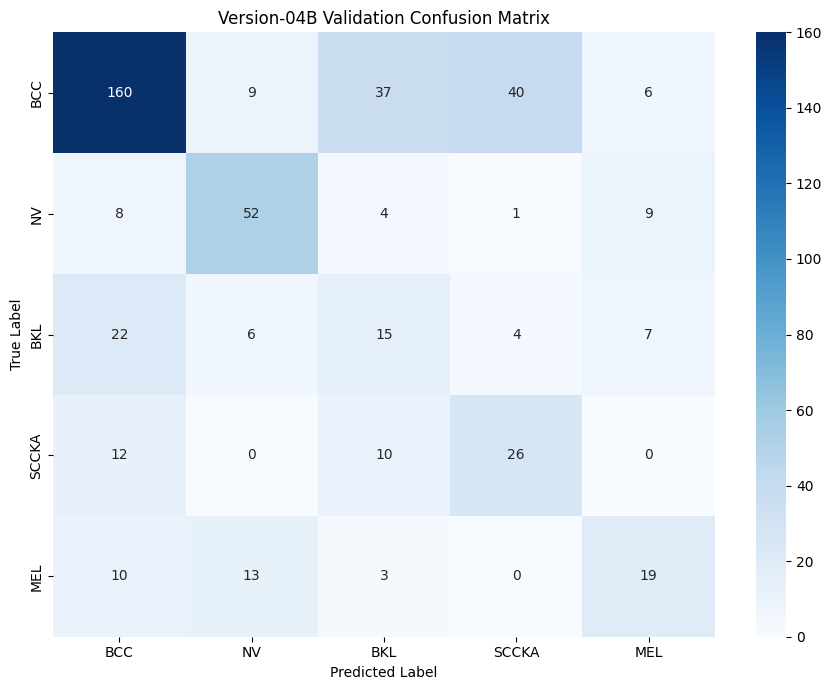

              precision    recall  f1-score   support

         BCC       0.75      0.63      0.69       252
          NV       0.65      0.70      0.68        74
         BKL       0.22      0.28      0.24        54
       SCCKA       0.37      0.54      0.44        48
         MEL       0.46      0.42      0.44        45

    accuracy                           0.58       473
   macro avg       0.49      0.52      0.50       473
weighted avg       0.61      0.58      0.59       473



In [29]:
from sklearn.metrics import confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

model.eval()

val_labels_5 = []
val_predictions_5 = []

with torch.no_grad():

    for clinical, dermoscopic, labels in val_loader:

        clinical = clinical.to(device)
        dermoscopic = dermoscopic.to(device)

        outputs = model(clinical, dermoscopic)
        predictions = outputs.argmax(dim=1)

        val_labels_5.extend(labels.cpu().numpy())
        val_predictions_5.extend(predictions.cpu().numpy())

        functional.reset_net(model)

val_cm_5 = confusion_matrix(
    val_labels_5,
    val_predictions_5,
    labels=list(range(len(class_names)))
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    val_cm_5,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Version-04B Validation Confusion Matrix")
plt.tight_layout()
plt.show()

print(classification_report(
    val_labels_5,
    val_predictions_5,
    labels=list(range(len(class_names))),
    target_names=class_names,
    zero_division=0
))

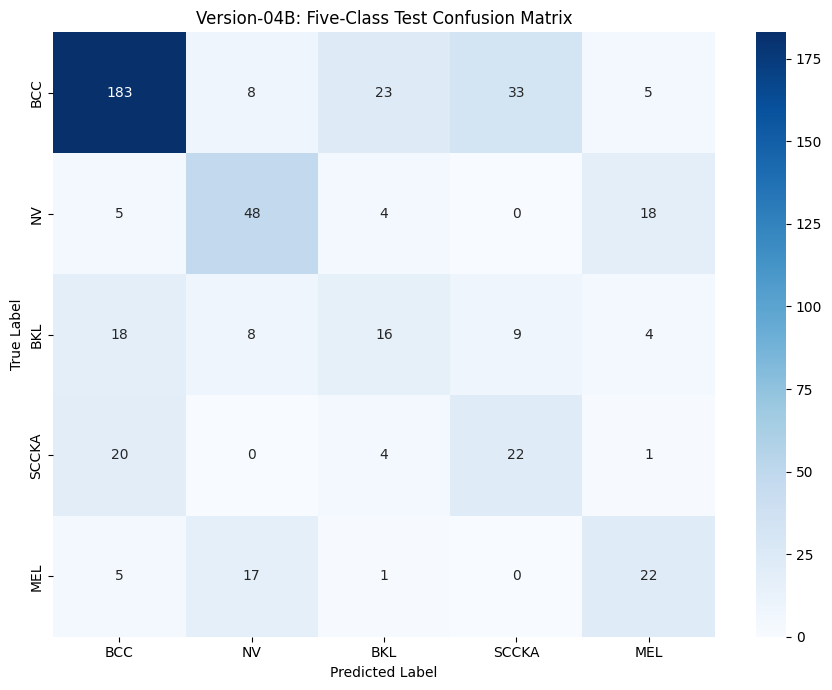

In [30]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm_5class = confusion_matrix(
    all_labels,
    all_predictions,
    labels=list(range(len(class_names)))
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm_5class,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Version-04B: Five-Class Test Confusion Matrix")
plt.tight_layout()
plt.show()

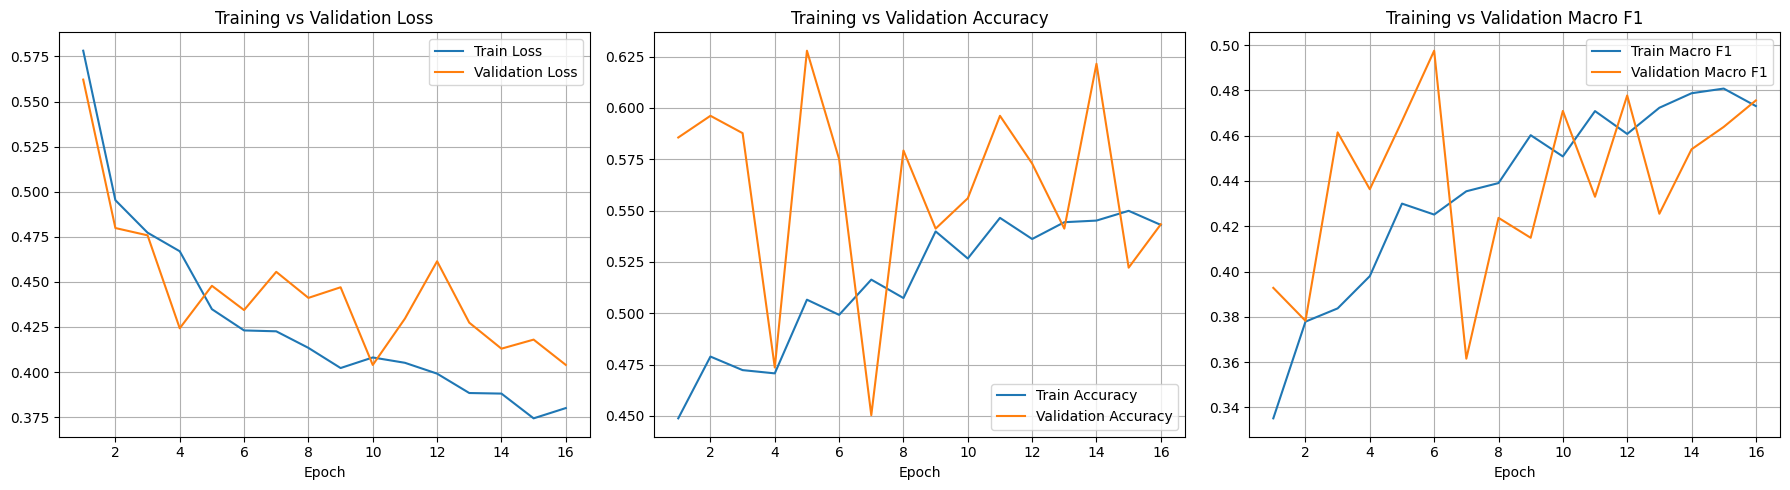

In [31]:
import matplotlib.pyplot as plt

epochs_range = range(1, len(history["train_loss"]) + 1)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Loss
axes[0].plot(epochs_range, history["train_loss"], label="Train Loss")
axes[0].plot(epochs_range, history["val_loss"], label="Validation Loss")
axes[0].set_title("Training vs Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].legend()
axes[0].grid(True)

# Accuracy
axes[1].plot(epochs_range, history["train_acc"], label="Train Accuracy")
axes[1].plot(epochs_range, history["val_acc"], label="Validation Accuracy")
axes[1].set_title("Training vs Validation Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].legend()
axes[1].grid(True)

# Macro F1
axes[2].plot(epochs_range, history["train_f1"], label="Train Macro F1")
axes[2].plot(epochs_range, history["val_f1"], label="Validation Macro F1")
axes[2].set_title("Training vs Validation Macro F1")
axes[2].set_xlabel("Epoch")
axes[2].legend()
axes[2].grid(True)

plt.tight_layout()
plt.show()